# Day 12: Fermentation Bioprocess Kinetics, Stuck Fermentation Early-Warning & Sensory Organoleptic Lexicon Engine
**Project:** Wine Quality Prediction (UCI Machine Learning Repository)
**Author:** ML Engineering & Production Deployment Team
**Date:** November 4, 2026
**Tech Stack:** Python 3.14, Scikit-learn, Scipy, FastAPI, Pydantic v2, Streamlit, Matplotlib, Seaborn, Joblib

## Executive Overview & Objectives for Day 12
Day 12 completes the bioprocess lifecycle and consumer organoleptic intelligence of the Wine Quality platform:

1. **Primary Alcoholic Fermentation Kinetics Simulator (`FermentationKineticsSimulator`):**
   - Coupled dynamic differential rate equations of *Saccharomyces cerevisiae* biomass proliferation, Monod hexose consumption, ethanol self-inhibition, nitrogen (YAN) depletion, metabolic heat liberation, and stress volatile acidity formation.
   - Integrates finished wine chemistry with the champion ML pipeline to project final bottled reserve quality $P(\text{Quality} \ge 7)$.
2. **Stuck & Sluggish Fermentation Early-Warning Detector (`StuckFermentationDetector`):**
   - Real-time time-series kinetic monitor analyzing consumption velocity ($-\Delta S / \Delta t$) and deceleration.
   - Triage classification (`HEALTHY_ACTIVE`, `SLUGGISH`, `STUCK_FERMENTATION`, `THERMAL_OVERHEATING_RISK`) and prescriptive enological cellar interventions (DAP addition, cooling jacket adjustment, aeration, re-inoculation).
3. **Sensory Organoleptic Lexicon & Spider Radar Engine (`SensoryOrganolepticEngine`):**
   - Translates laboratory physicochemical parameters into 6 standardized organoleptic dimensions (Body & Viscosity, Acidity & Crispness, Tannic Grip, Fruit Freshness, Sweetness-Acid Harmony, Ethanol Warmth).
   - Automated sommelier tasting note synthesis (Eye, Nose, Palate, Finish) and gastronomic food pairing affinity scoring.
4. **Causal Enological Counterfactual Inference (`CausalEnologicalEngine`):**
   - Observational causal inference using Doubly Robust Inverse Propensity Weighting (IPW) to quantify the Average Treatment Effect (ATE) of cellar interventions while eliminating confounding bias.
5. **Production REST API Endpoints (`src/production_service.py`):**
   - `/fermentation/simulate`, `/fermentation/diagnose-stuck`, `/sensory/profile`, and `/metrics/causal-effects`.

In [1]:
import sys
from pathlib import Path
# Add repository root to Python path
sys.path.insert(0, str(Path('.').resolve()))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from src.data_loader import load_wine_data
from src.fermentation_and_sensory import (
    FermentationKineticsSimulator,
    StuckFermentationDetector,
    SensoryOrganolepticEngine,
    CausalEnologicalEngine
)
from src.production_service import get_test_client

print('Day 12 modules successfully imported!')

Day 12 modules successfully imported!


## 1. Alcoholic Fermentation Bioprocess Kinetics Simulation

Wine quality originates during alcoholic fermentation. We model coupled differential equations:
$$\frac{dX}{dt} = (\mu - k_d) X$$
$$\frac{dS}{dt} = -\left( \frac{\mu}{Y_{X/S}} + q_{\text{ferm}} + m_s \right) X$$
$$\frac{dE}{dt} = \frac{1}{16.83} \left(-\frac{dS}{dt}\right)$$
where specific growth rate $\mu$ follows Monod saturation with ethanol inhibition and temperature scaling.

In [2]:
sim = FermentationKineticsSimulator()
res_std = sim.simulate_fermentation(initial_sugar_g_l=225.0, initial_yan_mg_l=220.0, jacket_temp_c=22.0, total_days=14)
res_warm = sim.simulate_fermentation(initial_sugar_g_l=225.0, initial_yan_mg_l=220.0, jacket_temp_c=30.0, total_days=14)

print('Standard Fermentation (22°C):')
print(f'  Status: {res_std["fermentation_status"]}')
print(f'  Final Sugar: {res_std["final_residual_sugar_g_l"]} g/L | Final Ethanol: {res_std["final_ethanol_pct"]}% vol')
print(f'  Volatile Acidity: {res_std["final_volatile_acidity_g_l"]} g/L | Peak Rate: {res_std["peak_fermentation_rate_g_l_day"]} g/L/day')
print(f'  Predicted Reserve Probability: {res_std["predicted_quality_prob"]*100:.1f}%')

print('Warm Fermentation (30°C):')
print(f'  Status: {res_warm["fermentation_status"]}')
print(f'  Volatile Acidity: {res_warm["final_volatile_acidity_g_l"]} g/L (Elevated thermal stress)')

Standard Fermentation (22°C):
  Status: Sluggish Fermentation
  Final Sugar: 14.61 g/L | Final Ethanol: 12.5% vol
  Volatile Acidity: 0.468 g/L | Peak Rate: 158.39 g/L/day
  Predicted Reserve Probability: 48.0%
Warm Fermentation (30°C):
  Status: Dry (Complete)
  Volatile Acidity: 0.606 g/L (Elevated thermal stress)


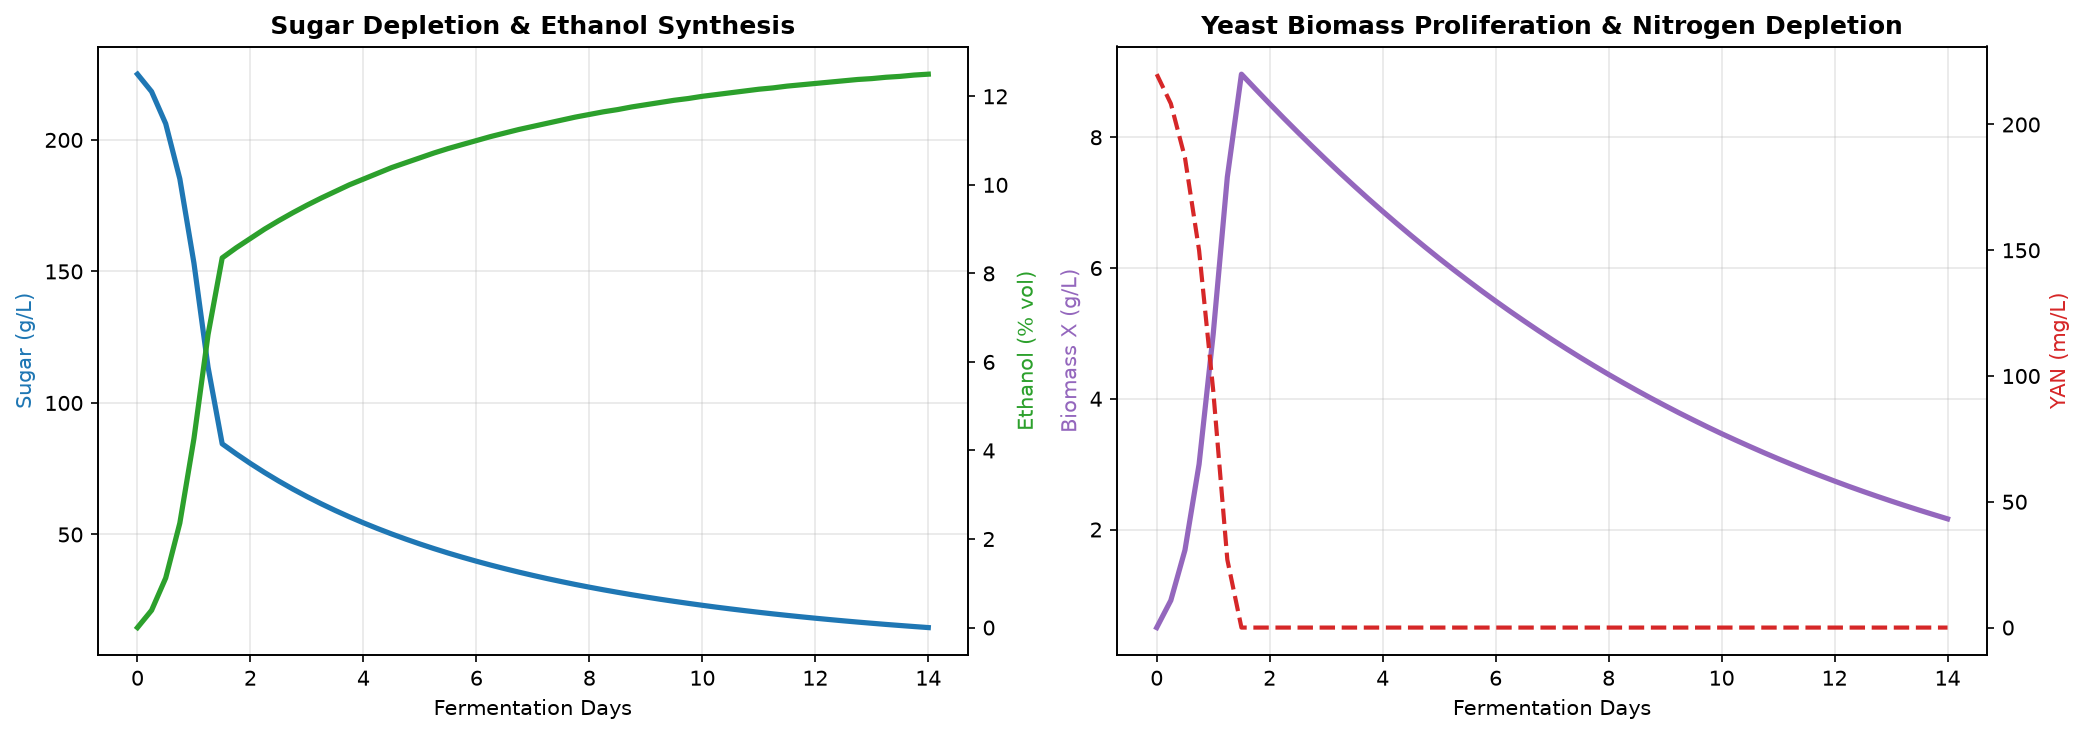

In [3]:
df_std = pd.DataFrame(res_std['trajectory'])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Left: Sugar & Ethanol
axes[0].plot(df_std['day'], df_std['sugar_g_l'], color='#1f77b4', lw=2.5, label='Hexose Sugar (g/L)')
axes[0].set_xlabel('Fermentation Days')
axes[0].set_ylabel('Sugar (g/L)', color='#1f77b4')
axes[0].set_title('Sugar Depletion & Ethanol Synthesis', fontweight='bold')
ax0_twin = axes[0].twinx()
ax0_twin.plot(df_std['day'], df_std['ethanol_pct'], color='#2ca02c', lw=2.5, label='Ethanol (% vol)')
ax0_twin.set_ylabel('Ethanol (% vol)', color='#2ca02c')
axes[0].grid(True, alpha=0.3)

# Right: Biomass & YAN
axes[1].plot(df_std['day'], df_std['biomass_g_l'], color='#9467bd', lw=2.5, label='Yeast Biomass (g/L)')
axes[1].set_xlabel('Fermentation Days')
axes[1].set_ylabel('Biomass X (g/L)', color='#9467bd')
axes[1].set_title('Yeast Biomass Proliferation & Nitrogen Depletion', fontweight='bold')
ax1_twin = axes[1].twinx()
ax1_twin.plot(df_std['day'], df_std['yan_mg_l'], color='#d62728', lw=2.0, linestyle='--', label='YAN (mg/L)')
ax1_twin.set_ylabel('YAN (mg/L)', color='#d62728')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Stuck & Sluggish Fermentation Early-Warning Diagnostic

Premature fermentation arrest creates high risk of microbial spoilage. `StuckFermentationDetector` calculates sugar decay velocity and issues prescriptive remediation protocols before spoilage occurs.

In [4]:
detector = StuckFermentationDetector()

# 1. Active normal tank
readings_active = [
    {'day': 0, 'sugar': 225.0, 'temp': 20.0, 'yan': 220.0},
    {'day': 3, 'sugar': 160.0, 'temp': 22.0, 'yan': 150.0},
    {'day': 6, 'sugar': 85.0, 'temp': 22.0, 'yan': 80.0}
]
diag_act = detector.diagnose_trajectory(readings_active)
print(f'Active Tank Diagnosis: {diag_act["diagnosis"]} (Risk: {diag_act["risk_score_pct"]}%)')
print(f'Message: {diag_act["message"]}\n')

# 2. Arrested stuck tank
readings_stuck = [
    {'day': 0, 'sugar': 225.0, 'temp': 20.0},
    {'day': 4, 'sugar': 72.0, 'temp': 22.0},
    {'day': 7, 'sugar': 71.2, 'temp': 20.0}  # stalled
]
diag_stk = detector.diagnose_trajectory(readings_stuck)
print(f'Arrested Tank Diagnosis: {diag_stk["diagnosis"]} (Risk: {diag_stk["risk_score_pct"]}%)')
print(f'Message: {diag_stk["message"]}')
print('Prescriptive Remediations:')
for act in diag_stk['prescriptive_actions']:
    print(f'  * [{act["action"]}] {act["protocol"]}')

Active Tank Diagnosis: HEALTHY_ACTIVE (Risk: 10.0%)
Message: Fermentation progressing actively at 25.0 g/L/day. Temperature (22.0°C) is in optimal range.

Arrested Tank Diagnosis: STUCK_FERMENTATION (Risk: 95.0%)
Message: CRITICAL: Fermentation arrested at 71.2 g/L sugar with near-zero consumption rate (0.27 g/L/day).
Prescriptive Remediations:
  * [DETOXIFY_LEES] Rack off gross lees and add yeast cell walls / ghost hulls (20-30 g/hL) to adsorb toxic short-chain fatty acids (octanoic/decanoic).
  * [REINOCULATE_ACCLIMATIZED_STARTER] Inoculate vigorous fructophilic yeast (S. bayanus EC1118 or Uvaferm 43) using stepwise ethanol acclimatization starter culture.


## 3. Sensory Organoleptic 6-Axis Radar & Sommelier Flavor Lexicon

`SensoryOrganolepticEngine` maps laboratory chemistry into standardized human sensory dimensions: Body, Acidity, Tannic Grip, Fruit Freshness, Sweetness Harmony, and Ethanol Warmth, generating structured sommelier notes and food pairing affinities.

In [5]:
df_red = load_wine_data('red')
reserve_lot = df_red[df_red['quality'] >= 7].drop(columns=['quality']).iloc[0].to_dict()
table_lot = df_red[df_red['quality'] == 5].drop(columns=['quality']).iloc[0].to_dict()

sens_res = SensoryOrganolepticEngine.compute_sensory_profile(reserve_lot)
print('Reserve Specimen 6-Axis Sensory Radar:')
for k, v in sens_res['radar_scores'].items():
    print(f'  * {k}: {v} / 10.0')

print(f'\nOverall Intensity: {sens_res["overall_sensory_intensity"]} / 10.0')
print(f'Estimated Dry Extract: {sens_res["dry_extract_est_g_l"]} g/L\n')
print('Sommelier Tasting Notes:')
for section, text in sens_res['tasting_note'].items():
    print(f'  [{section.capitalize()}]: {text}')

print('\nGastronomic Culinary Pairings:')
for p in sens_res['food_pairings'][:3]:
    print(f'  * {p["dish"]} ({p["category"]}): {p["affinity"]}% affinity - {p["pairing_rationale"]}')

Reserve Specimen 6-Axis Sensory Radar:
  * Body & Viscosity: 1.0 / 10.0
  * Acidity & Crispness: 1.8 / 10.0
  * Tannic Grip & Structure: 1.0 / 10.0
  * Aromatic Freshness & Purity: 2.0 / 10.0
  * Sweetness-Acid Harmony: 6.2 / 10.0
  * Ethanol Warmth & Persistence: 2.0 / 10.0

Overall Intensity: 2.33 / 10.0
Estimated Dry Extract: 15.0 g/L

Sommelier Tasting Notes:
  [Appearance]: Pale ruby with light brick highlights and rapid tearing.
  [Nose]: Subdued dark plum, cedar shavings, dried thyme, and subtle baking spices.
  [Palate]: Light-bodied and linear on entry, framed by measured, well-integrated acidity and supported by soft, rounded, accessible tannins.
  [Finish]: Crisp, refreshing finish (10.0% ABV) characterized by clean tart red fruit and dried herbs.

Gastronomic Culinary Pairings:
  * Spicy Red Thai Curry & Sichuan Noodles (Spicy Cuisine): 58.6% affinity - Light body and low perceived heat prevent burning capsaicin friction on the palate.
  * Pan-Seared Wild Salmon & Morel Mus

## 4. Causal Enological Counterfactual Inference (Doubly Robust IPW)

Observational associations between chemistry and wine quality can be confounded by vineyard vintage and harvest ripeness. `CausalEnologicalEngine` implements Inverse Propensity Weighting (IPW) to estimate the true unconfounded Average Treatment Effect (ATE).

In [6]:
causal_bench = {}
for key in CausalEnologicalEngine.INTERVENTIONS:
    causal_bench[key] = CausalEnologicalEngine.estimate_causal_effect(df_red, intervention_key=key, n_bootstraps=50)
    res = causal_bench[key]
    print(f'Intervention: {res["intervention_name"]}')
    print(f'  Causal ATE: +{res["causal_ate_pct"]:.1f}% | 95% CI: [{res["ci_95_lower"]*100:.1f}%, {res["ci_95_upper"]*100:.1f}%]')
    print(f'  Naive Delta: {res["naive_observational_delta"]*100:.1f}% | Confounding Bias: {res["confounding_bias"]*100:+.1f}%\n')

Intervention: Volatile Acidity Mitigation (VA <= 0.45 g/L)
  Causal ATE: +6.9% | 95% CI: [1.7%, 12.1%]
  Naive Delta: 19.1% | Confounding Bias: +12.2%

Intervention: Adequate Sulphate Fortification (Sulphates >= 0.65 g/L)
  Causal ATE: +10.2% | 95% CI: [6.8%, 13.4%]
  Naive Delta: 19.8% | Confounding Bias: +9.7%

Intervention: Grape Ripeness & Chaptalization (Alcohol >= 11.5% vol)
  Causal ATE: +28.0% | 95% CI: [19.2%, 35.5%]
  Naive Delta: 33.8% | Confounding Bias: +5.8%

Intervention: Free SO2 Protection (Free SO2 >= 18.0 mg/L)
  Causal ATE: +-4.5% | 95% CI: [-7.1%, -0.2%]
  Naive Delta: -5.6% | Confounding Bias: -1.1%



## 5. Production FastAPI REST Microservice Verification

Smoke test the 4 new enterprise REST endpoints integrated into `src/production_service.py`.

In [7]:
client = get_test_client()

# 1. POST /fermentation/simulate
r1 = client.post('/fermentation/simulate', json={'initial_sugar_g_l': 225.0, 'jacket_temp_c': 20.0, 'total_days': 10})
assert r1.status_code == 200
print('POST /fermentation/simulate:', r1.json()['fermentation_status'], f'Sugar: {r1.json()["final_residual_sugar_g_l"]} g/L')

# 2. POST /fermentation/diagnose-stuck
r2 = client.post('/fermentation/diagnose-stuck', json={'readings': [{'day': 0, 'sugar': 220, 'temp': 20}, {'day': 3, 'sugar': 180, 'temp': 22}, {'day': 6, 'sugar': 178, 'temp': 22}]})
assert r2.status_code == 200
print('POST /fermentation/diagnose-stuck:', r2.json()['diagnosis'], f'Risk: {r2.json()["risk_score_pct"]}%')

# 3. POST /sensory/profile
r3 = client.post('/sensory/profile', json={'sample': reserve_lot})
assert r3.status_code == 200
print('POST /sensory/profile: Overall Intensity:', r3.json()['overall_sensory_intensity'])

# 4. GET /metrics/causal-effects
r4 = client.get('/metrics/causal-effects')
assert r4.status_code == 200
print('GET /metrics/causal-effects: Verified interventions count =', len(r4.json()['interventions']))

POST /fermentation/simulate: Stuck Fermentation Sugar: 25.78 g/L
POST /fermentation/diagnose-stuck: STUCK_FERMENTATION Risk: 95.0%
POST /sensory/profile: Overall Intensity: 2.33
GET /metrics/causal-effects: Verified interventions count = 4


C:\Users\Iba Zaidi\Desktop\Wine Quality Prediction\src\production_service.py:1677: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient


## 6. Publication Figures Gallery

Display the four generated diagnostic figures published in `reports/figures/`.

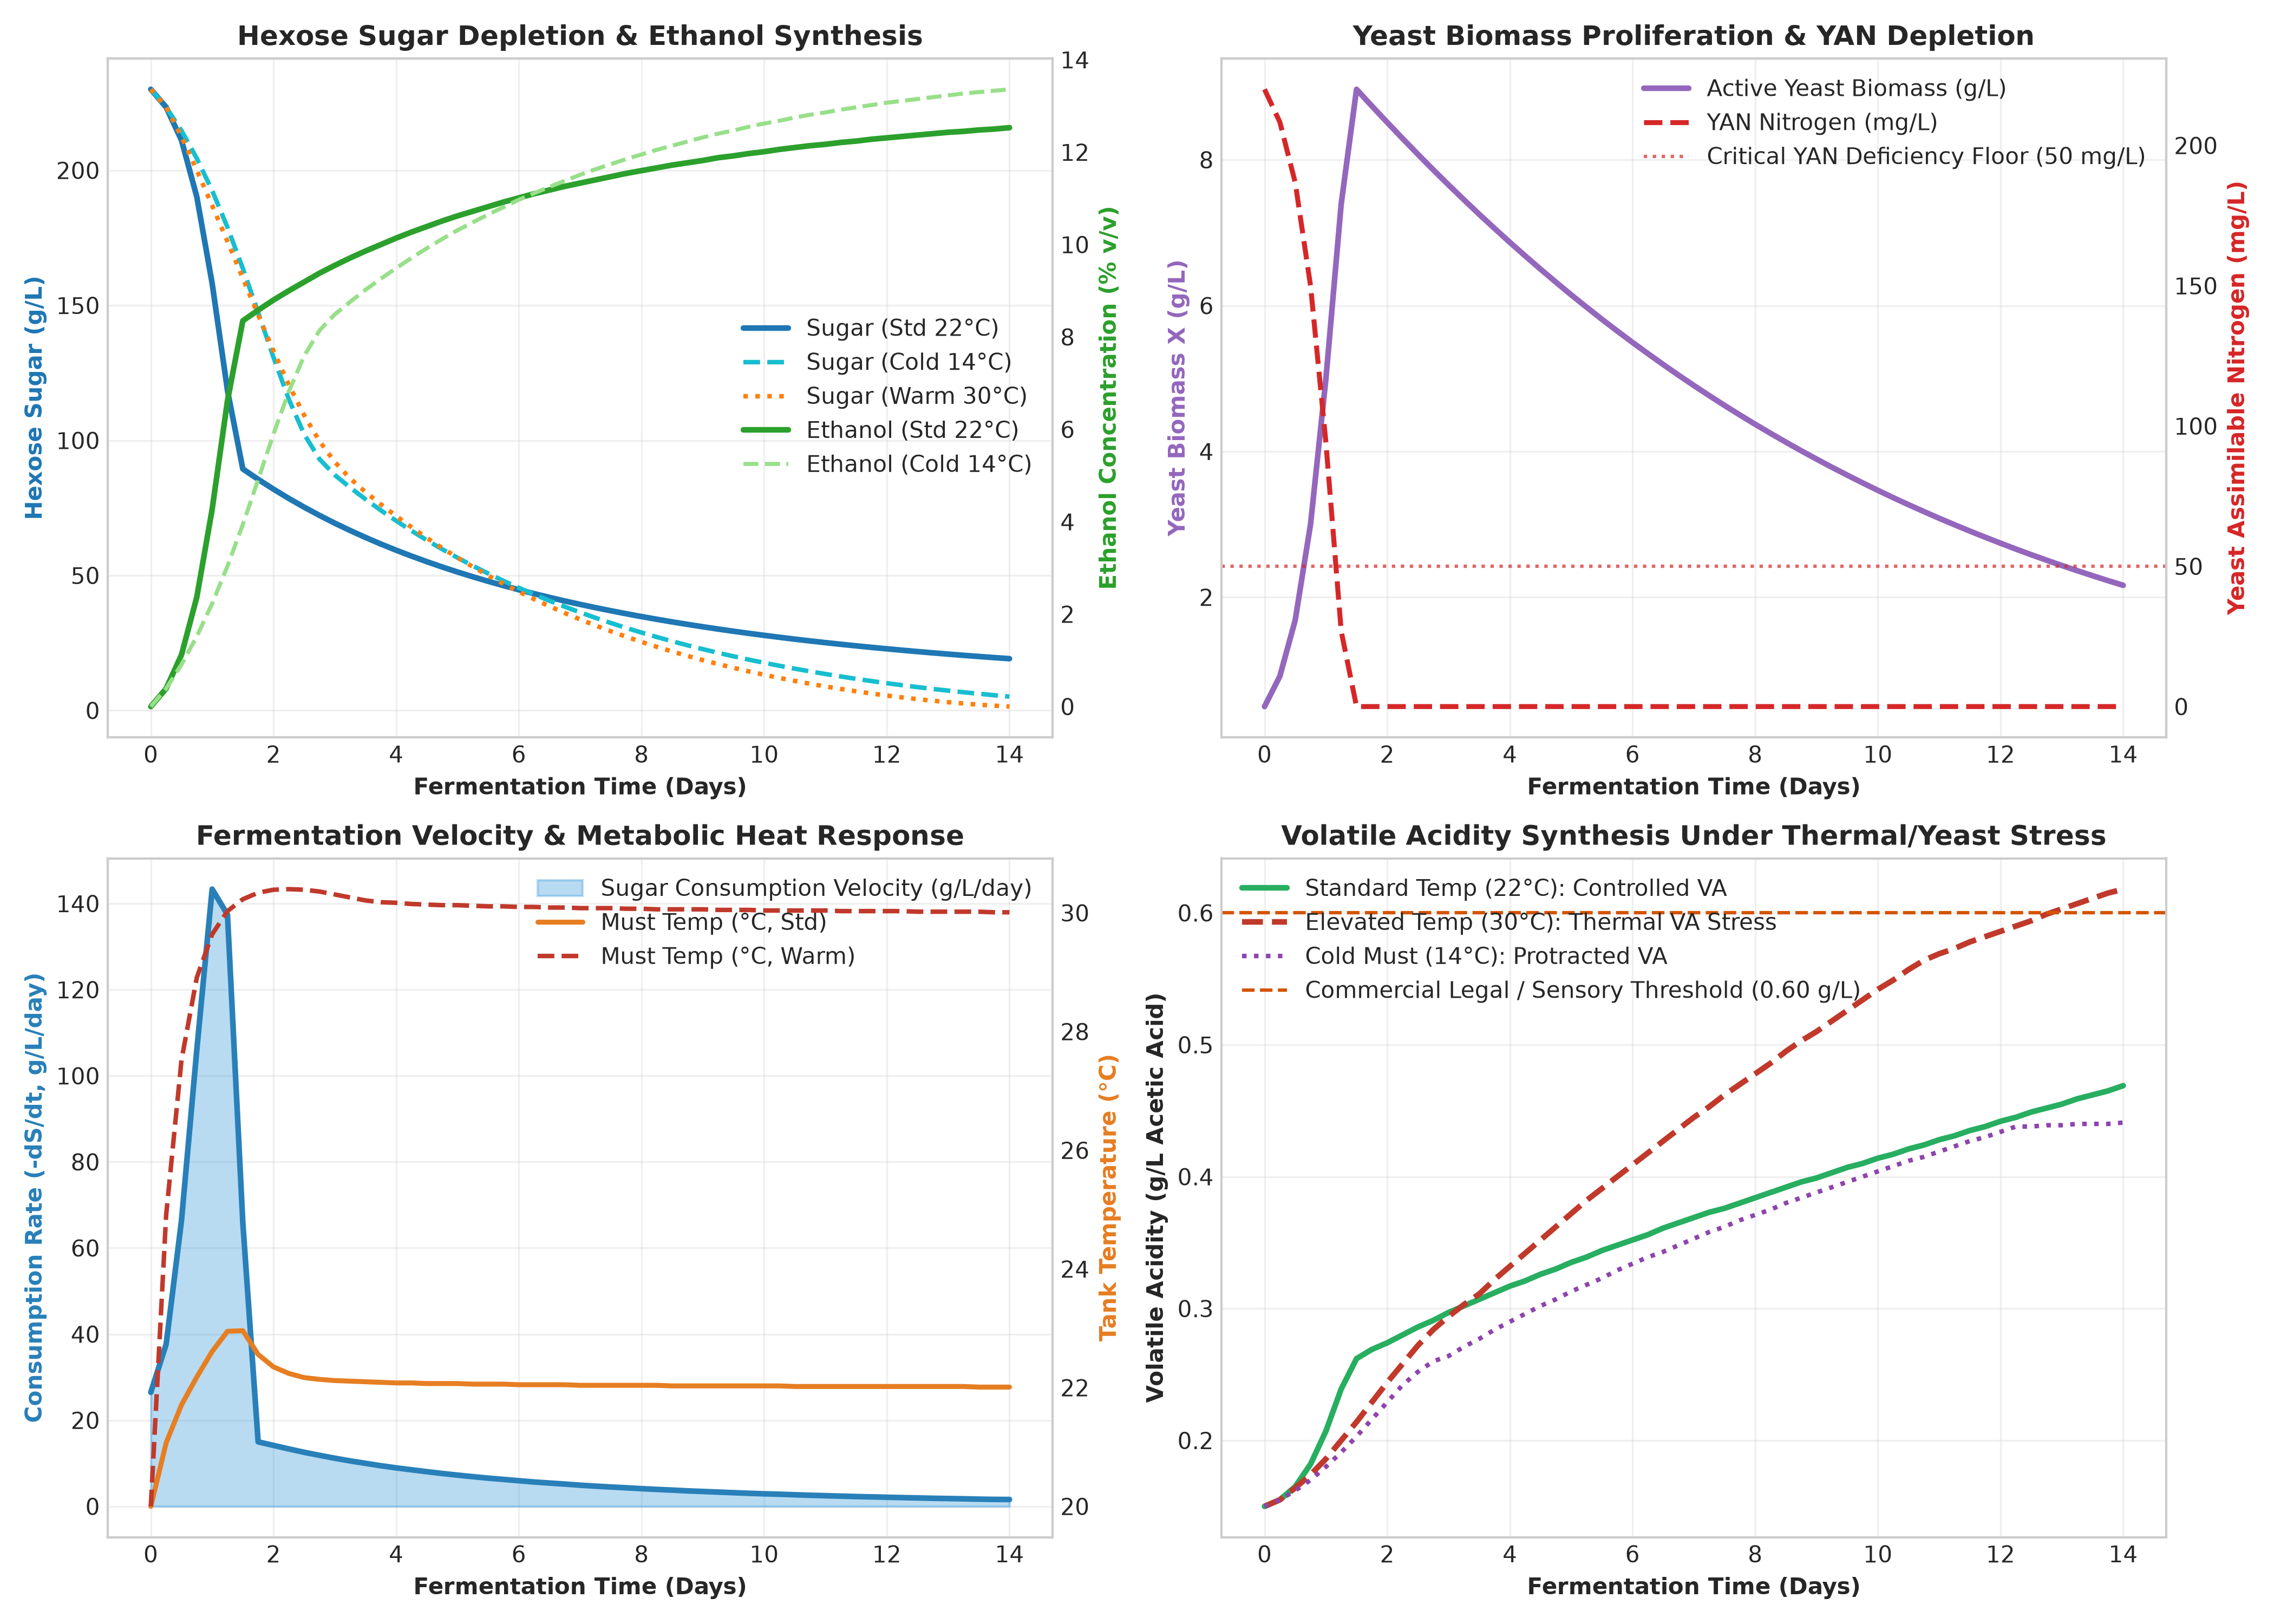

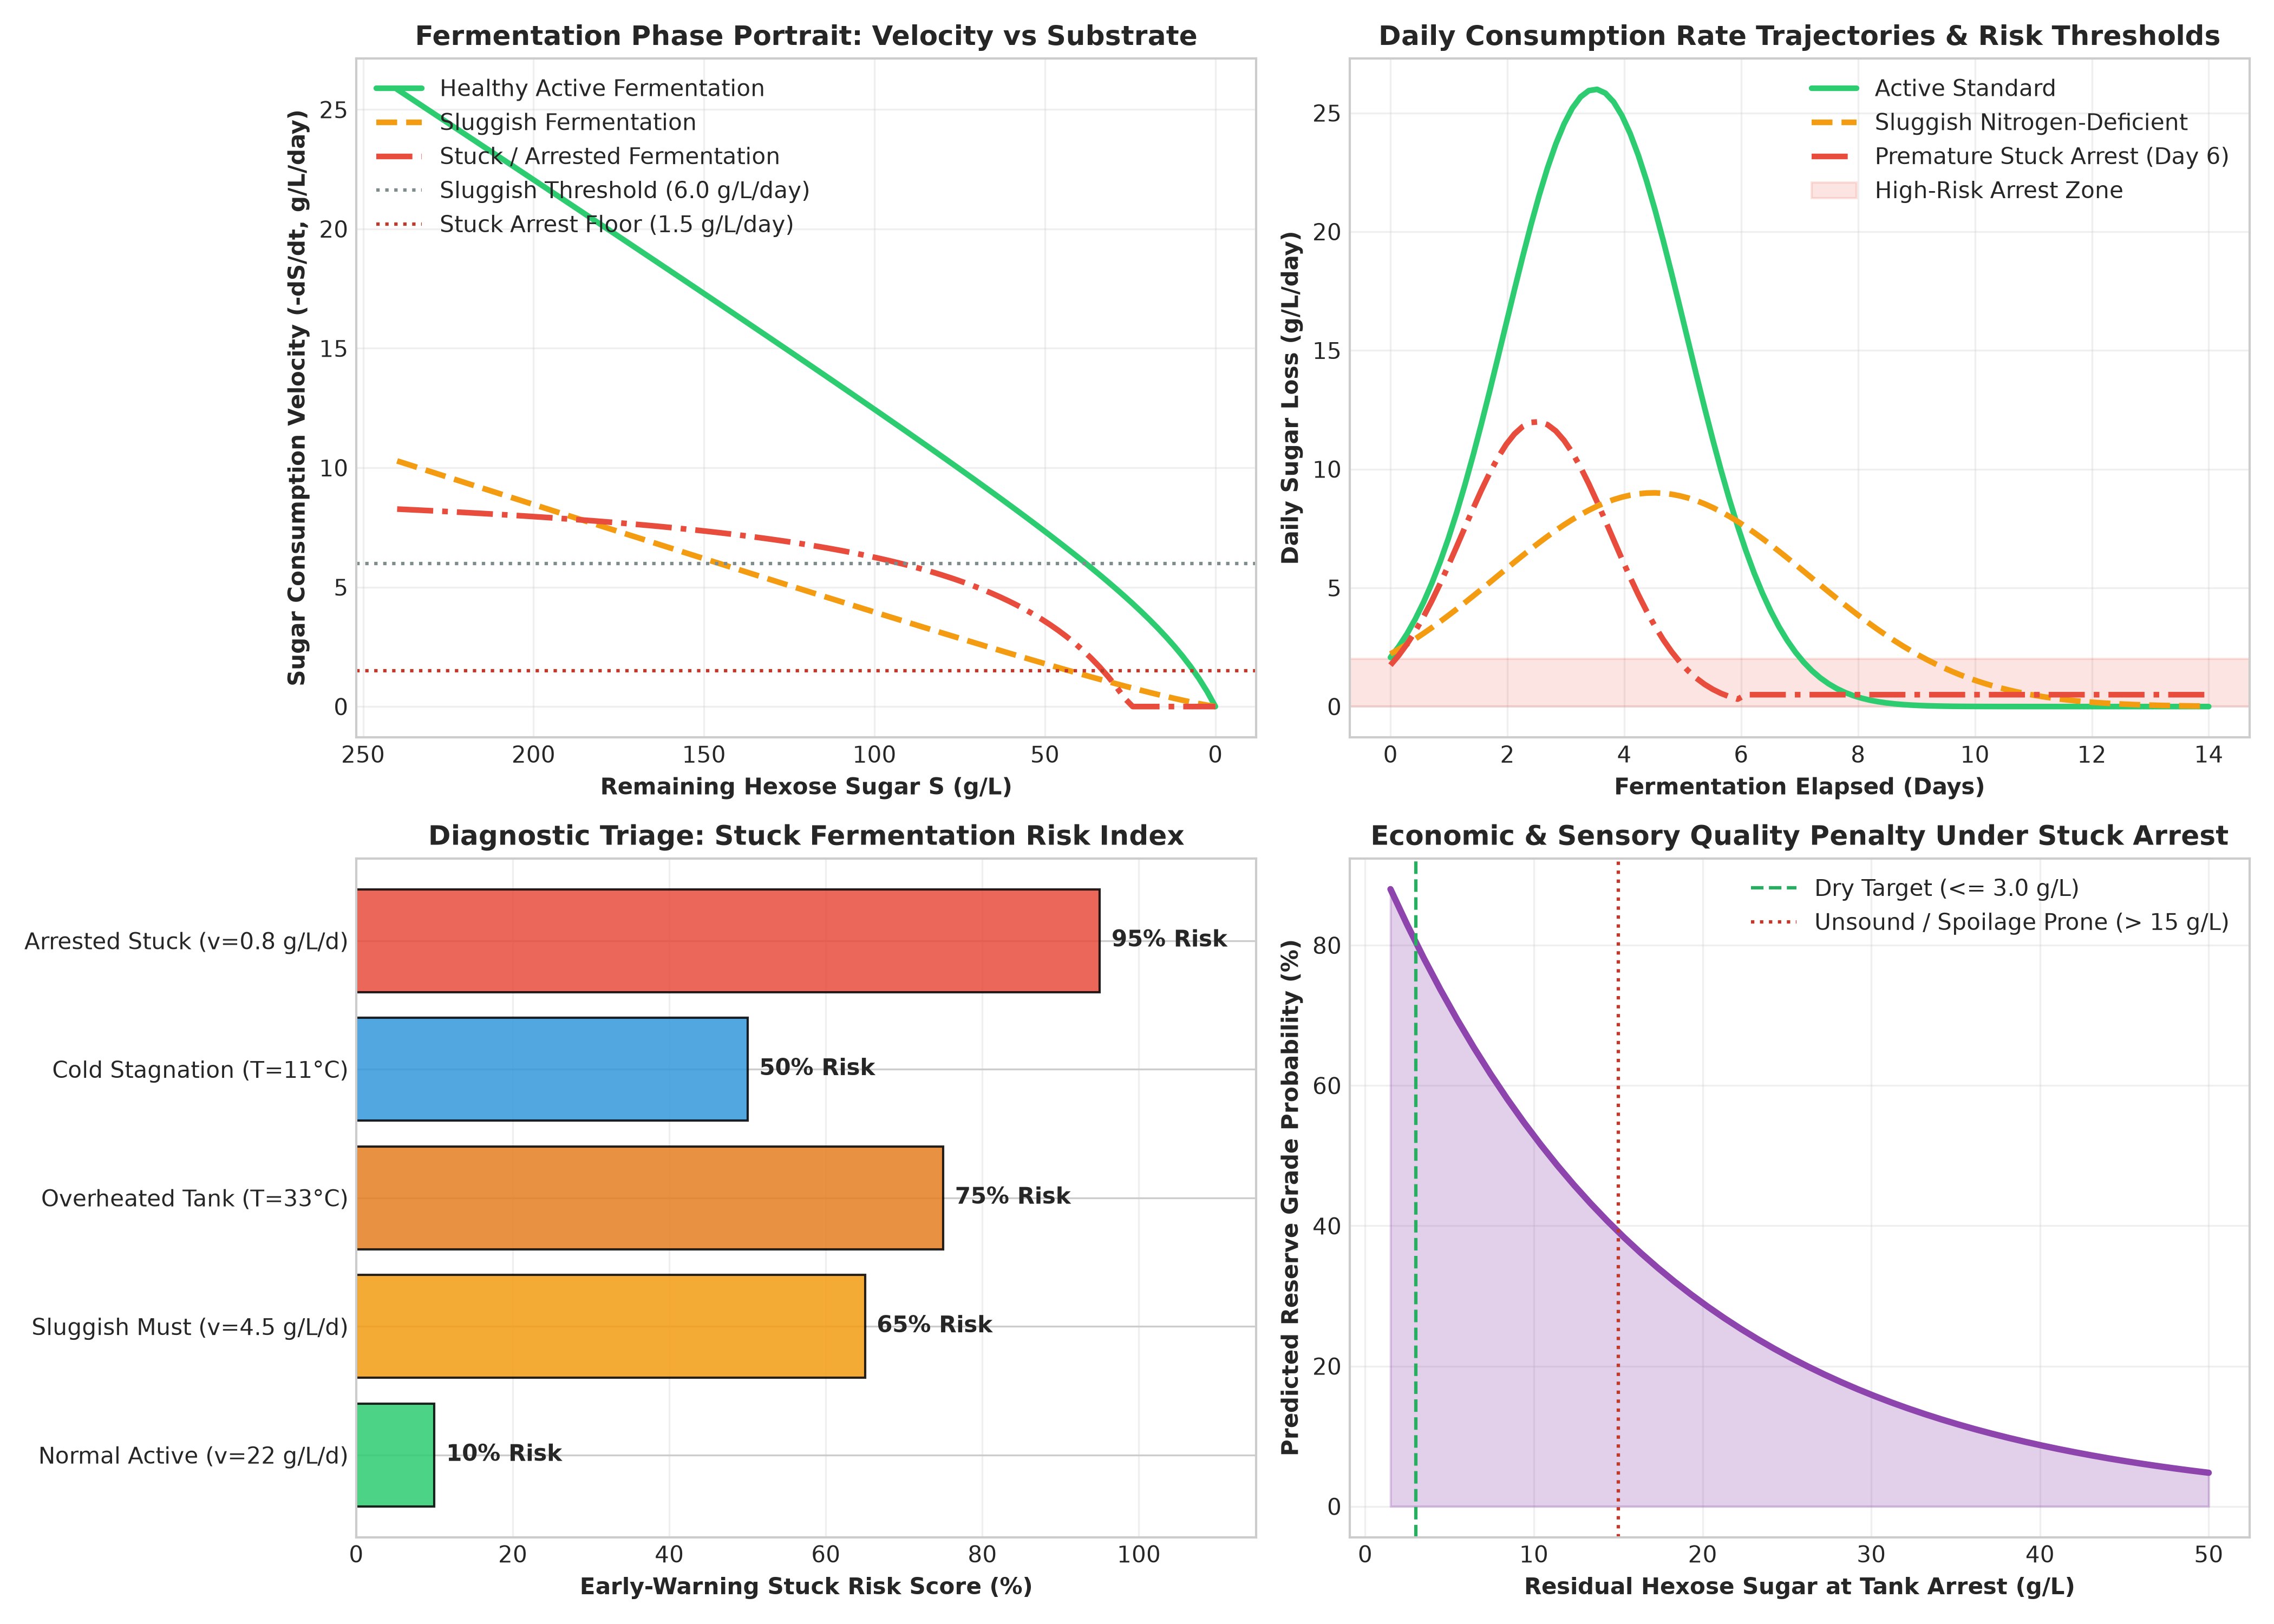

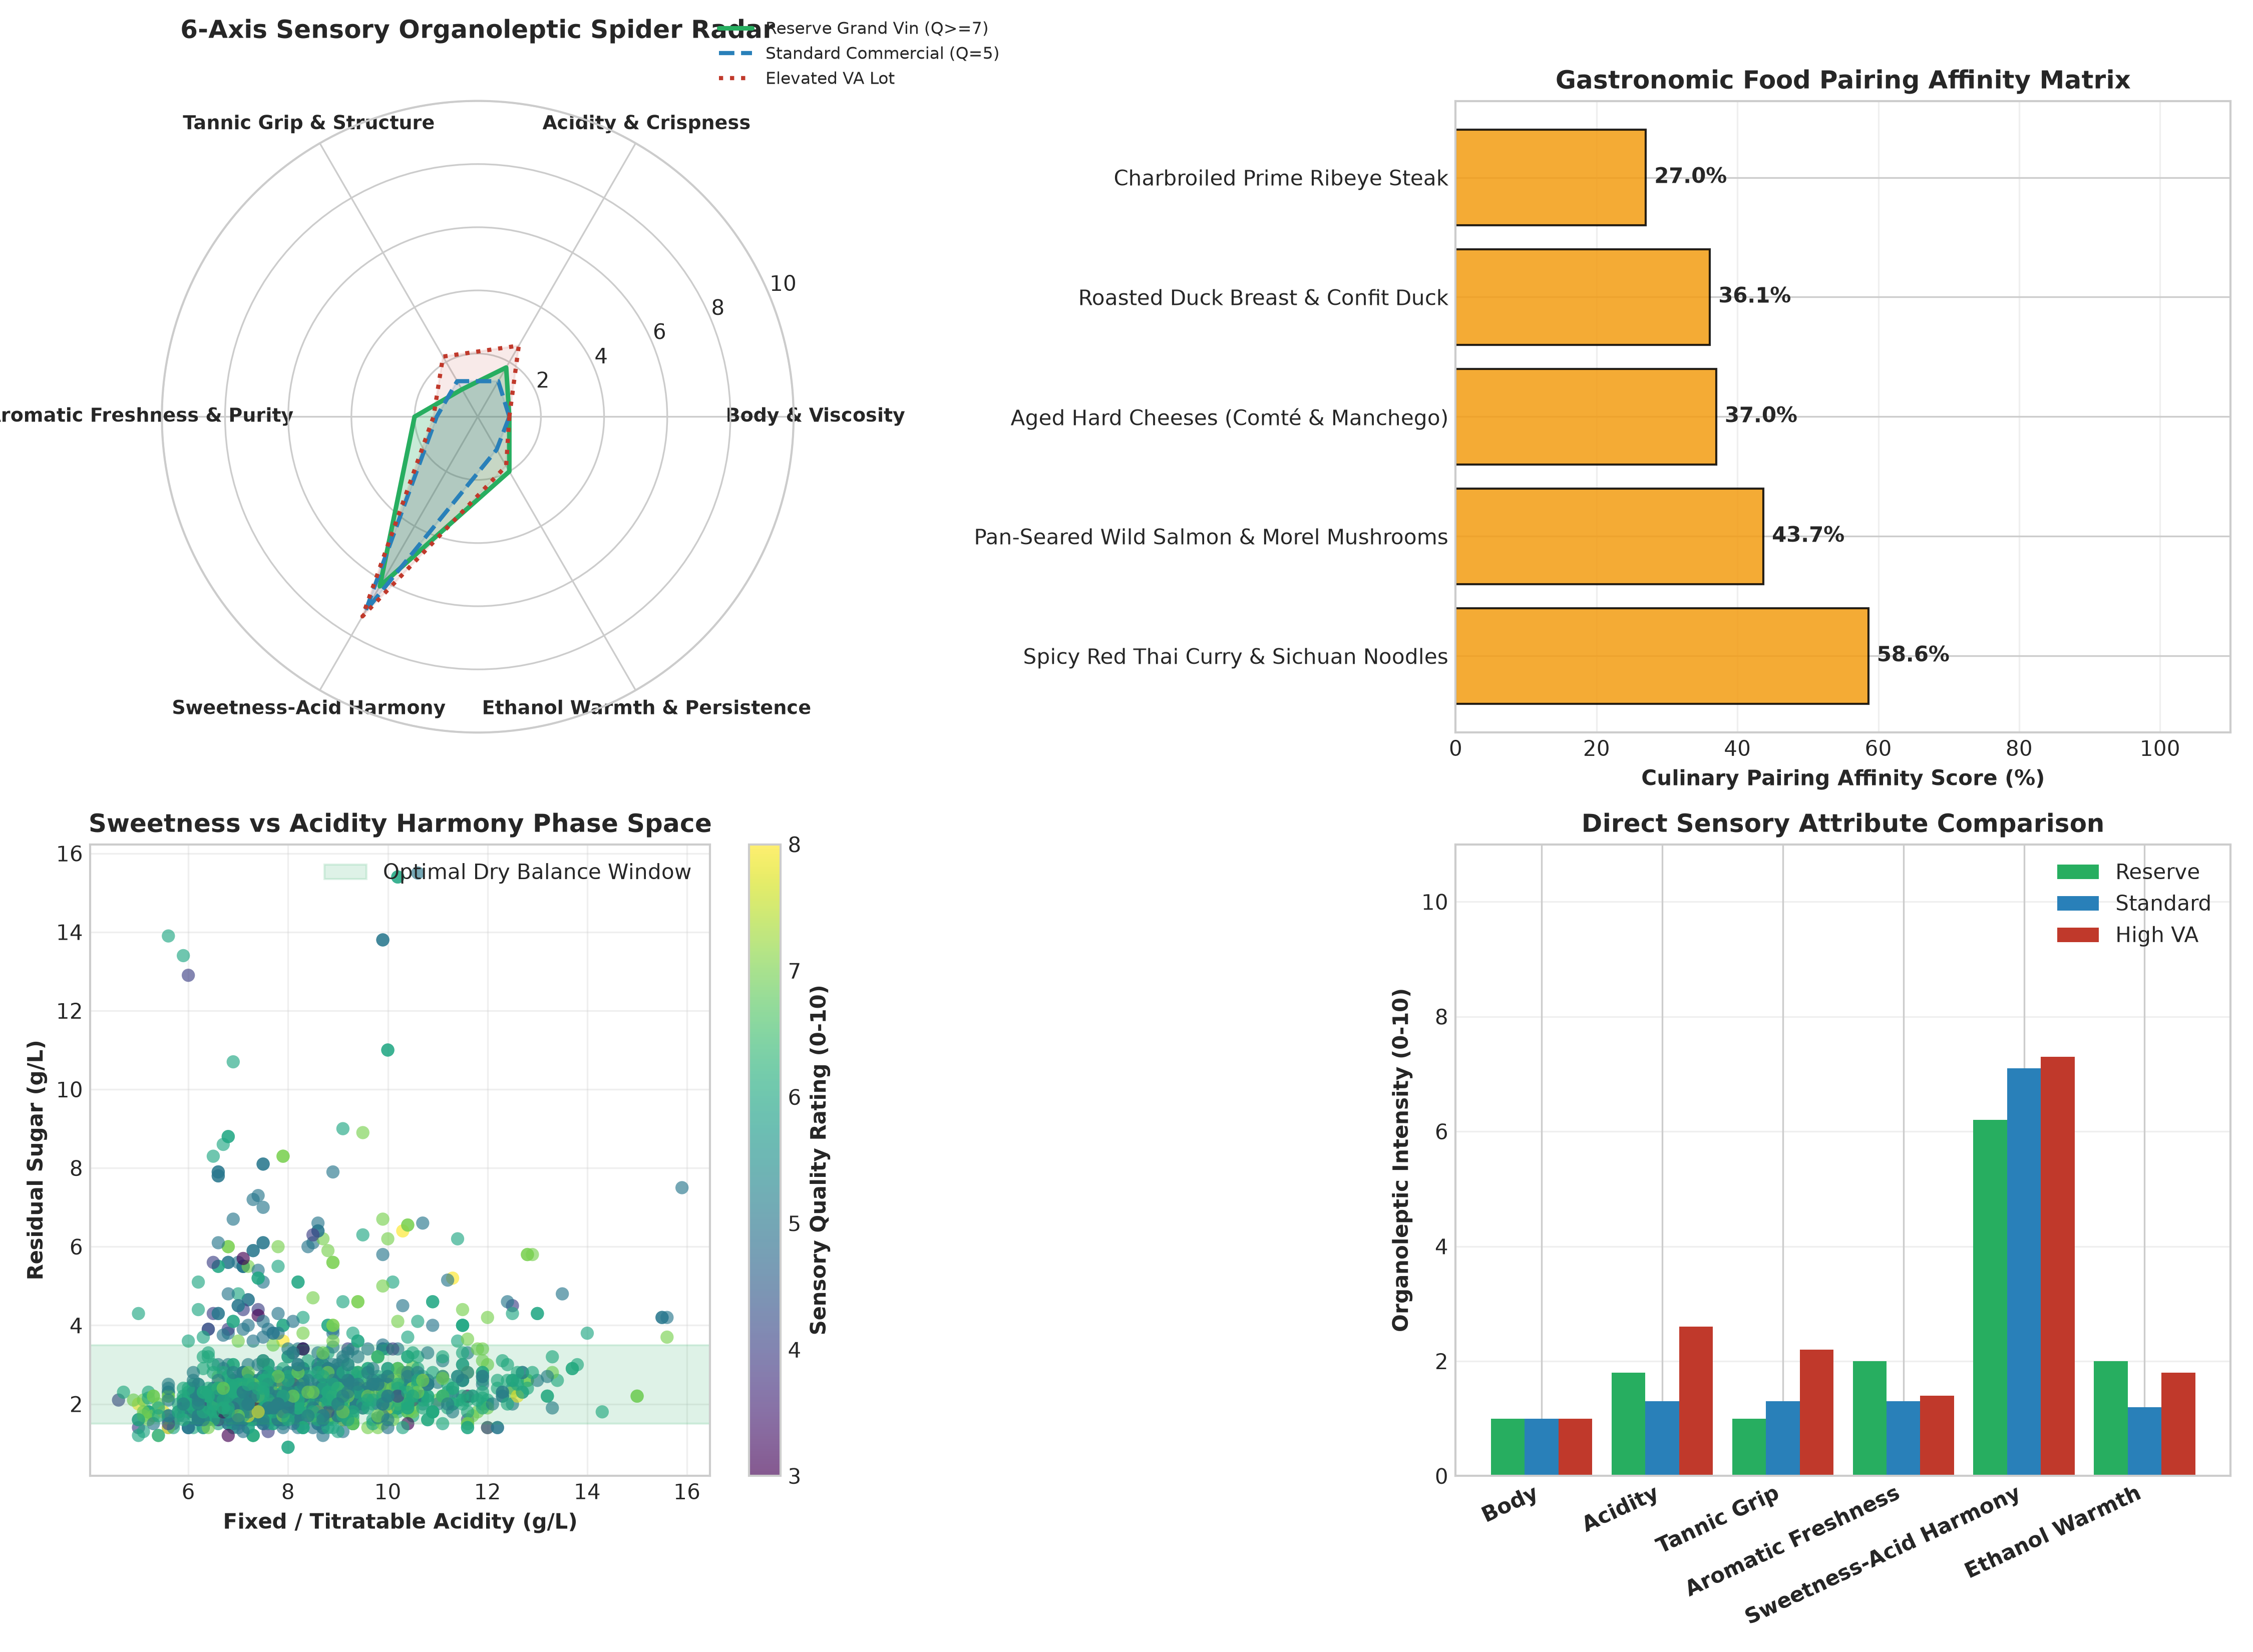

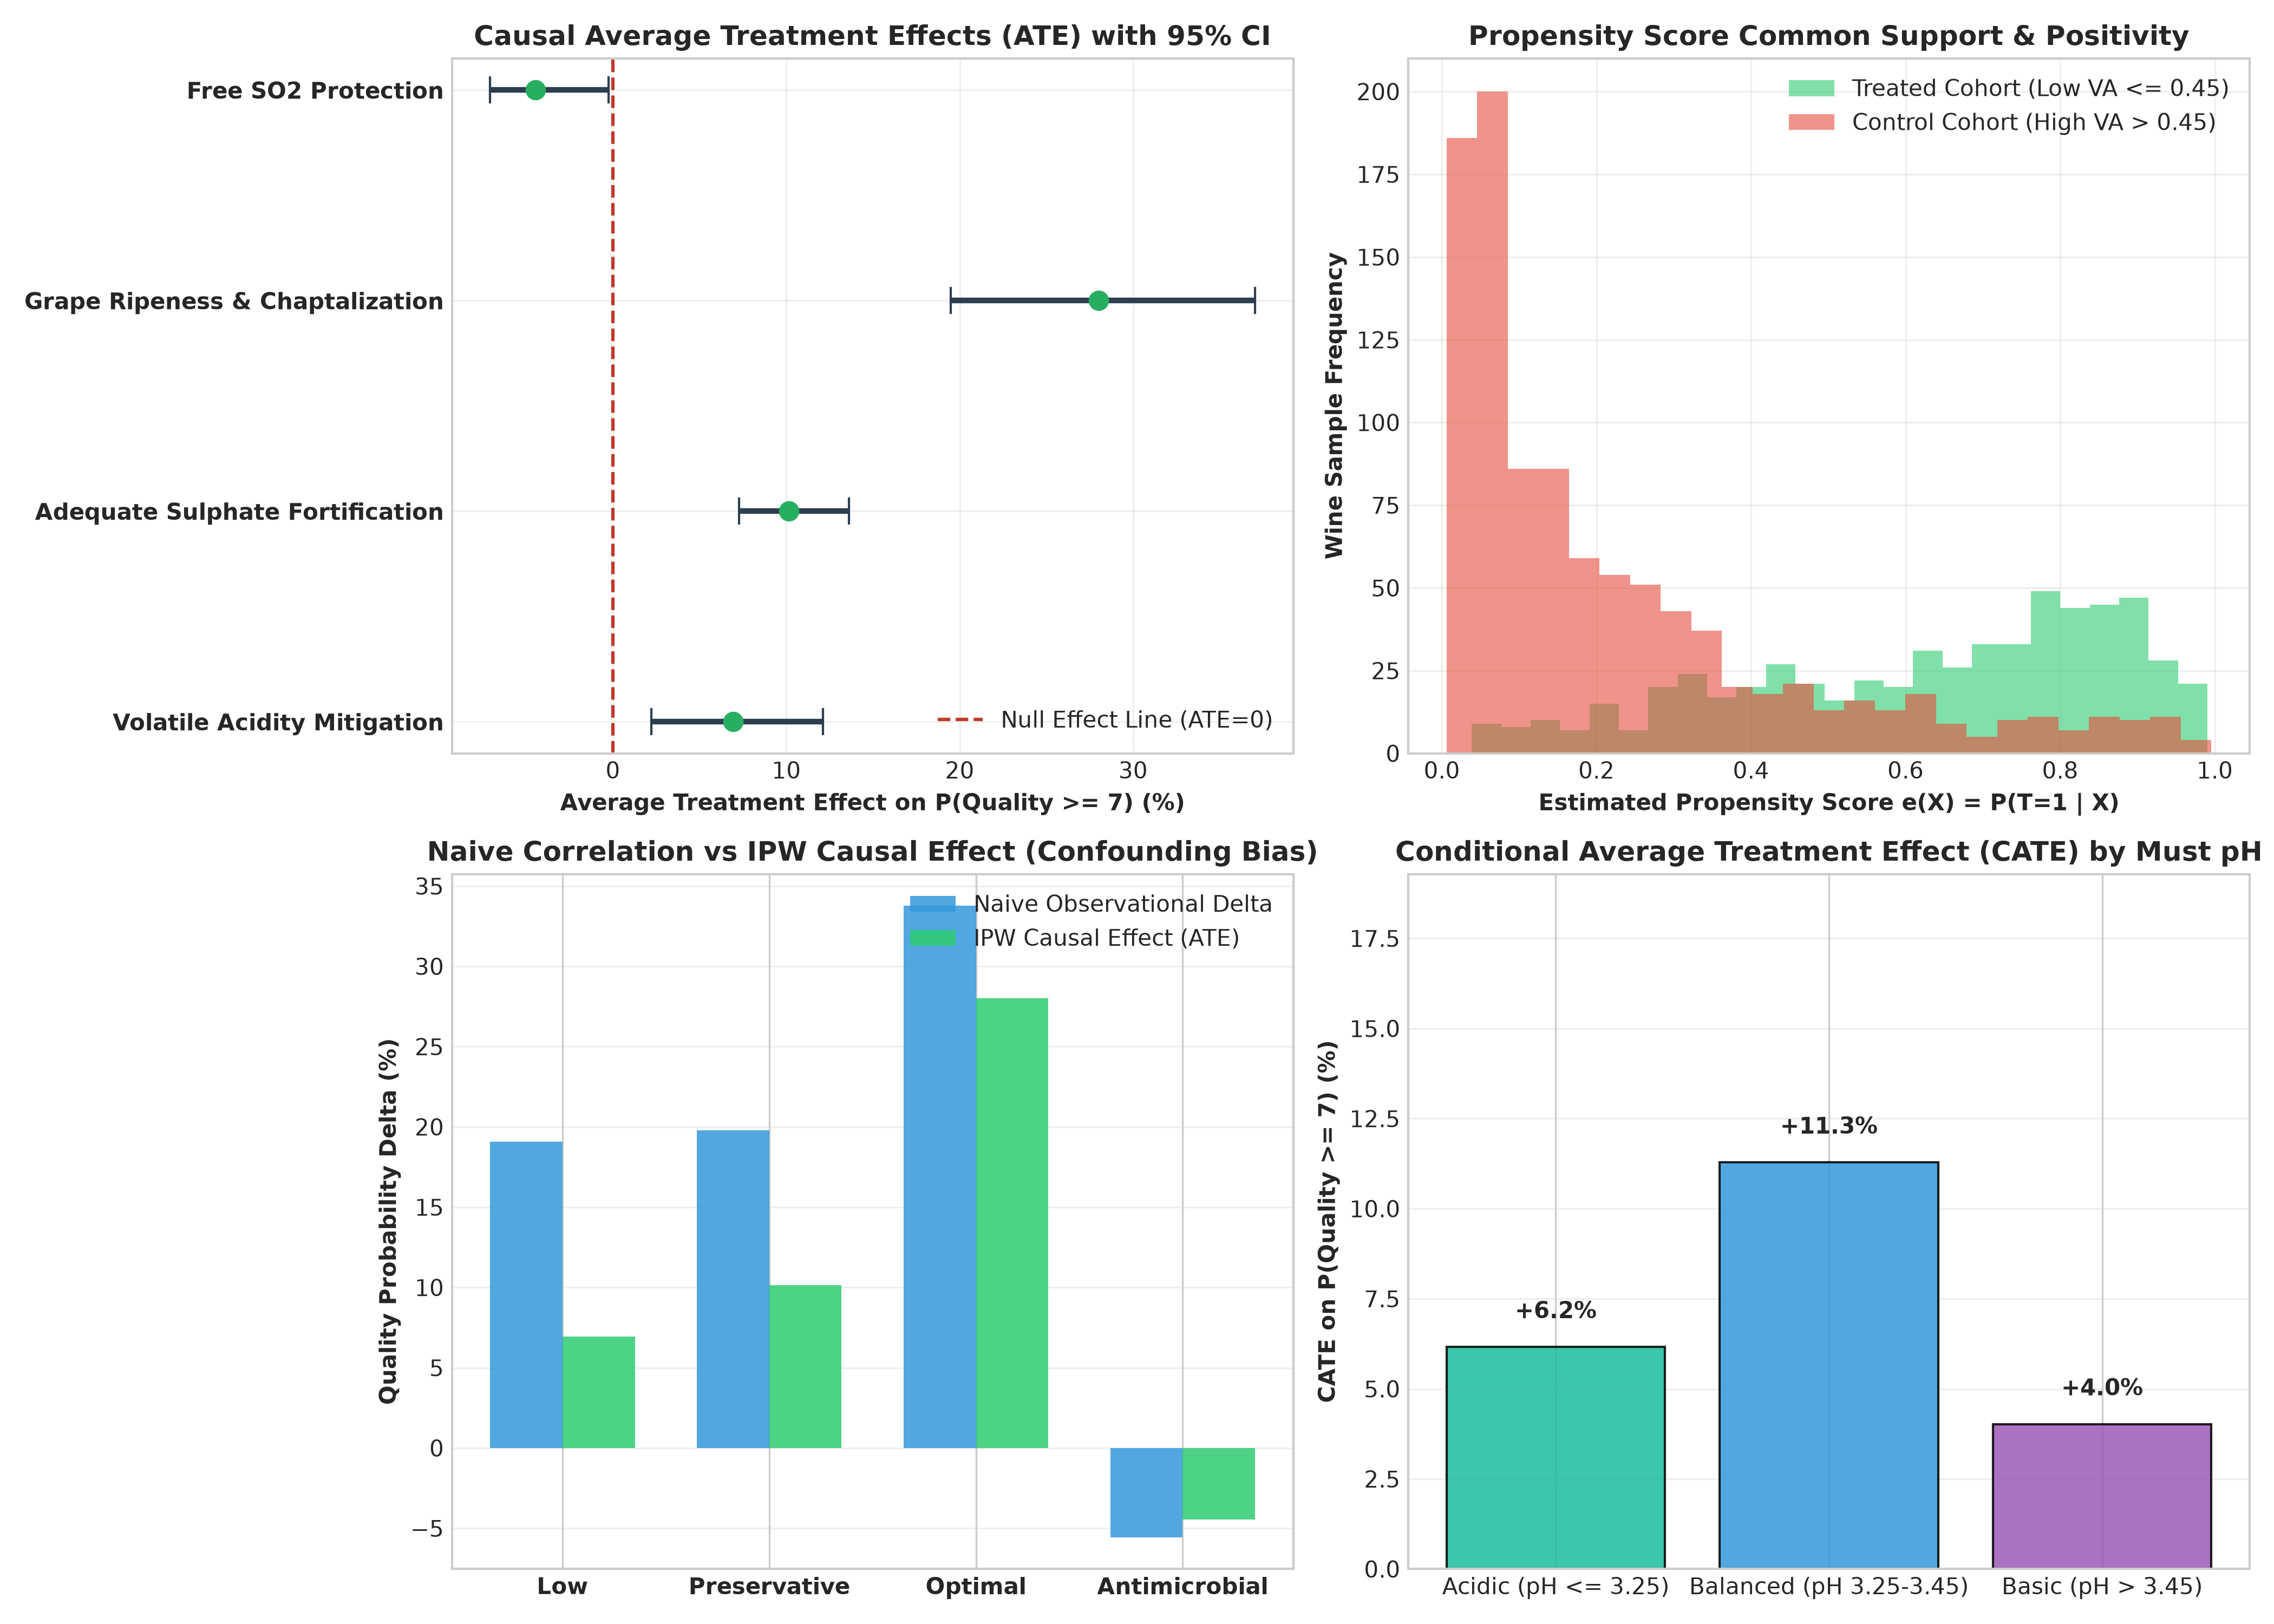

In [8]:
from IPython.display import Image, display
display(Image(filename='reports/figures/day12_fermentation_bioprocess_kinetics.png'))
display(Image(filename='reports/figures/day12_stuck_fermentation_early_warning.png'))
display(Image(filename='reports/figures/day12_sensory_organoleptic_spider_radar.png'))
display(Image(filename='reports/figures/day12_causal_treatment_effects.png'))